# Дополнительная лабораторная работа 5. Ассоциативные правила

Вариант 1: датасет Groceries (https://www.kaggle.com/datasets/irfanasrullah/groceries), начальные параметры для Apriori и FP-Growth: поддержка 0.03, достоверность 0.3.

## 1. Загрузка и описание данных

In [1]:
import pandas as pd
import seaborn as sns
import networkx as nx
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

all_data = pd.read_csv('groceries - groceries.csv')
all_data.head()

,Item(s),Item 1,Item 2,Item 3,Item 4,Item 5,Item 6,Item 7,Item 8,Item 9,...,Item 23,Item 24,Item 25,Item 26,Item 27,Item 28,Item 29,Item 30,Item 31,Item 32
0,4,citrus fruit,semi-finished bread,margarine,ready soups,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3,tropical fruit,yogurt,coffee,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,whole milk,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,pip fruit,yogurt,cream cheese,meat spreads,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,other vegetables,whole milk,condensed milk,long life bakery product,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Загрузил датасет Groceries с Kaggle. В таблице 9835 строк, каждая строка — одна покупка. Первый столбец `Item(s)` хранит число товаров в чеке, остальные 32 столбца — сами товары, пустые ячейки означают, что товаров в чеке меньше.

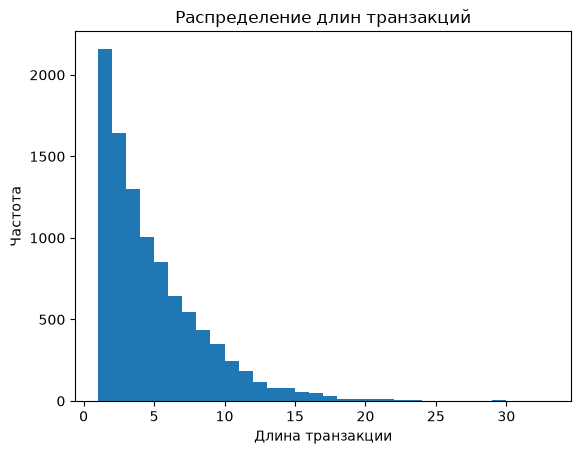

count    9835.000000
mean        4.409456
std         3.589385
min         1.000000
25%         2.000000
50%         3.000000
75%         6.000000
max        32.000000
dtype: float64

In [2]:
transaction_lengths = all_data.drop(columns='Item(s)').notnull().sum(axis=1)

plt.hist(transaction_lengths, bins=range(1, transaction_lengths.max() + 2))
plt.xlabel('Длина транзакции')
plt.ylabel('Частота')
plt.title('Распределение длин транзакций')
plt.show()

transaction_lengths.describe()

Построил распределение длин транзакций. В исходном коде из `ass_rules.pdf` длина считалась по всем столбцам, включая `Item(s)`, поэтому каждая транзакция получалась длиннее на единицу и гистограмма начиналась с 2. Я убрал этот столбец из подсчёта, и теперь длина равна реальному числу товаров. Значения совпадают со столбцом `Item(s)`.

Средняя длина транзакции 4.4 товара, медиана 3, максимум 32. Чаще всего встречаются чеки из одного товара (2159 транзакций, около 22%), а транзакции из 1–3 товаров составляют примерно 52% всех покупок. Чеки длиннее 10 товаров редки, их около 6.6%. Распределение сильно скошено вправо.

In [3]:
np_data = [[item for item in row[1:] if isinstance(item, str)] for row in all_data.to_numpy()]

unique_items = sorted({item for row in np_data for item in row})
len(unique_items)

169

In [4]:
unique_items

['Instant food products',
 'UHT-milk',
 'abrasive cleaner',
 'artif. sweetener',
 'baby cosmetics',
 'baby food',
 'bags',
 'baking powder',
 'bathroom cleaner',
 'beef',
 'berries',
 'beverages',
 'bottled beer',
 'bottled water',
 'brandy',
 'brown bread',
 'butter',
 'butter milk',
 'cake bar',
 'candles',
 'candy',
 'canned beer',
 'canned fish',
 'canned fruit',
 'canned vegetables',
 'cat food',
 'cereals',
 'chewing gum',
 'chicken',
 'chocolate',
 'chocolate marshmallow',
 'citrus fruit',
 'cleaner',
 'cling film/bags',
 'cocoa drinks',
 'coffee',
 'condensed milk',
 'cooking chocolate',
 'cookware',
 'cream',
 'cream cheese',
 'curd',
 'curd cheese',
 'decalcifier',
 'dental care',
 'dessert',
 'detergent',
 'dish cleaner',
 'dishes',
 'dog food',
 'domestic eggs',
 'female sanitary products',
 'finished products',
 'fish',
 'flour',
 'flower (seeds)',
 'flower soil/fertilizer',
 'frankfurter',
 'frozen chicken',
 'frozen dessert',
 'frozen fish',
 'frozen fruits',
 'frozen me

Очистил данные: убрал пустые ячейки и столбец `Item(s)`, получил список транзакций `np_data`. Составил отсортированный список уникальных товаров, в нём 169 позиций.

In [5]:
te = TransactionEncoder()
data = pd.DataFrame(te.fit(np_data).transform(np_data), columns=te.columns_)
data.shape

(9835, 169)

Преобразовал транзакции в бинарную таблицу one-hot: 9835 строк и 169 столбцов, значение `True` означает, что товар есть в чеке.

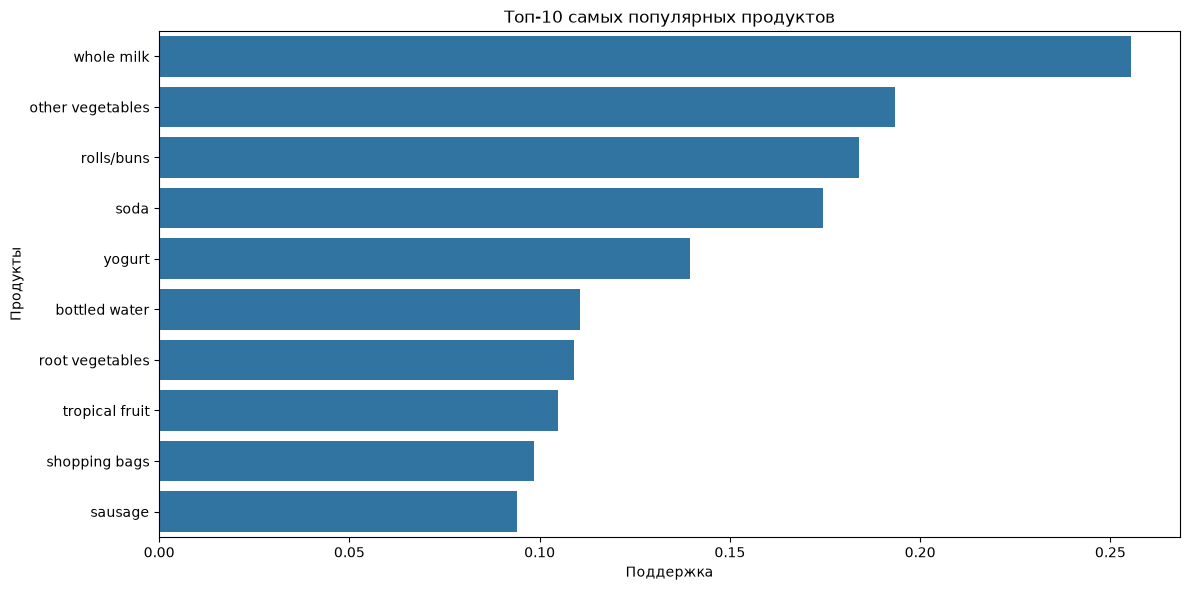

In [6]:
top_products = data.mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_products.values, y=top_products.index)
plt.title('Топ-10 самых популярных продуктов')
plt.xlabel('Поддержка')
plt.ylabel('Продукты')
plt.tight_layout()
plt.show()

Посчитал поддержку каждого товара как долю чеков, в которых он встречается, и вывел топ-10. Лидируют `whole milk` (0.256), `other vegetables` (0.194), `rolls/buns` (0.184), `soda` (0.174) и `yogurt` (0.140). Замыкают десятку `shopping bags` (0.099) и `sausage` (0.094).

Поддержка быстро убывает: при пороге 0.03 в частые наборы из одиночных товаров попадают только 44 товара из 169, а у 81 товара поддержка ниже 0.01. Поэтому при выбранных 0.03 правил будет немного, и их составят в основном самые популярные товары.

## 2. Алгоритм Apriori

In [7]:
MIN_SUPPORT, MIN_CONFIDENCE = 0.03, 0.3

def show(rules):
    r = rules.assign(antecedents=rules['antecedents'].apply(lambda x: ', '.join(sorted(x))),
                     consequents=rules['consequents'].apply(lambda x: ', '.join(sorted(x))))
    return r[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values('lift', ascending=False).round(3).reset_index(drop=True)

frequent_apriori = apriori(data, min_support=MIN_SUPPORT, use_colnames=True)
rules_apriori = association_rules(frequent_apriori, metric='confidence', min_threshold=MIN_CONFIDENCE)
frequent_apriori['itemsets'].apply(len).value_counts()

itemsets
1    44
2    19
Name: count, dtype: int64

Запустил Apriori с поддержкой 0.03 и достоверностью 0.3. Нашёл 63 частых набора: 44 из одного товара и 19 из двух товаров. Наборов из трёх товаров с такой поддержкой нет, поэтому все правила имеют вид «один товар → один товар». Всего получилось 14 правил.

In [8]:
show(rules_apriori)

,antecedents,consequents,support,confidence,lift
0,root vegetables,other vegetables,0.047,0.435,2.247
1,sausage,rolls/buns,0.031,0.326,1.771
2,tropical fruit,other vegetables,0.036,0.342,1.768
3,whipped/sour cream,whole milk,0.032,0.450,1.760
4,root vegetables,whole milk,0.049,0.449,1.756
5,yogurt,other vegetables,0.043,0.311,1.608
6,tropical fruit,whole milk,0.042,0.403,1.578
7,yogurt,whole milk,0.056,0.402,1.572
8,pip fruit,whole milk,0.030,0.398,1.557
9,other vegetables,whole milk,0.075,0.387,1.514


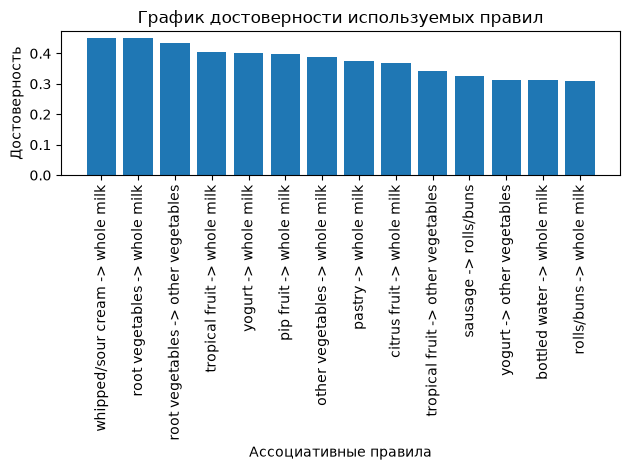

In [9]:
shown = show(rules_apriori).sort_values('confidence', ascending=False)
labels = shown['antecedents'] + ' -> ' + shown['consequents']

plt.bar(labels, shown['confidence'])
plt.xlabel('Ассоциативные правила')
plt.ylabel('Достоверность')
plt.title('График достоверности используемых правил')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [10]:
pd.Series({'правил с lift < 1': (rules_apriori['lift'] < 1).sum(),
           'правил с lift >= 1.5': (rules_apriori['lift'] >= 1.5).sum(),
           'правил со следствием whole milk': rules_apriori['consequents'].apply(lambda x: 'whole milk' in x).sum()})

правил с lift < 1                   0
правил с lift >= 1.5               10
правил со следствием whole milk    10
dtype: int64

Вывел правила, отсортированные по lift, и построил график достоверности. Достоверность правил лежит в диапазоне от 0.31 до 0.45, самые высокие значения у `whipped/sour cream → whole milk` и `root vegetables → whole milk`.

Lift у всех 14 правил больше 1, то есть ни одна связь не слабее случайного совпадения, а у 10 правил lift не меньше 1.5. Десять из 14 правил имеют следствие `whole milk`. Эта группа требует осторожности: молоко есть в 25.6% чеков, поэтому высокая достоверность таких правил отчасти объясняется только его популярностью. Правила `bottled water → whole milk` (lift 1.22) и `rolls/buns → whole milk` (lift 1.21) я считаю тривиальными: их достоверность около 0.31 почти не выше обычной доли молока в чеке.

Полезными считаю правила с самым высоким lift: `root vegetables → other vegetables` (достоверность 0.44, lift 2.25), `sausage → rolls/buns` (0.33, lift 1.77) и `tropical fruit → other vegetables` (0.34, lift 1.77). Они показывают связки внутри категорий (овощи и фрукты, колбаса и булочки), которые можно использовать для выкладки и совместных акций. Среди правил со следствием `whole milk` содержательнее остальных `root vegetables → whole milk` и `whipped/sour cream → whole milk` (lift около 1.76).

## 3. Влияние параметров Apriori на правила

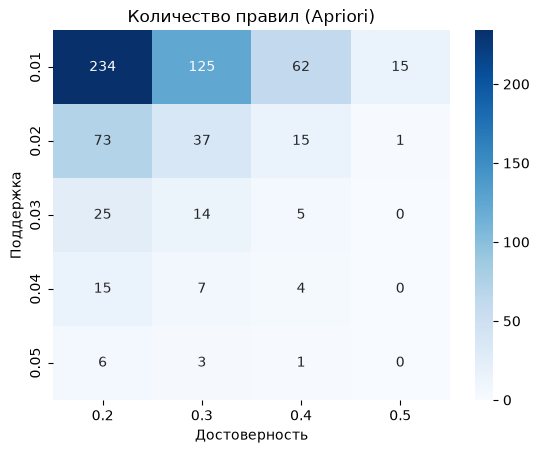

,частых наборов,"ср. lift, conf=0.2","ср. lift, conf=0.3","ср. lift, conf=0.4","ср. lift, conf=0.5"
0.01,333,1.81,1.91,1.99,2.30
0.02,122,1.63,1.73,1.86,2.01
0.03,63,1.50,1.60,1.78,NaN
0.04,41,1.53,1.64,1.79,NaN
0.05,31,1.43,1.43,1.57,NaN


In [11]:
supports = [0.01, 0.02, 0.03, 0.04, 0.05]
confidences = [0.2, 0.3, 0.4, 0.5]

counts = pd.DataFrame(index=supports, columns=confidences, dtype=float)
mean_lift = counts.copy()
n_itemsets = {}
for s in supports:
    frequent = apriori(data, min_support=s, use_colnames=True)
    n_itemsets[s] = len(frequent)
    for c in confidences:
        r = association_rules(frequent, metric='confidence', min_threshold=c)
        counts.loc[s, c] = len(r)
        mean_lift.loc[s, c] = r['lift'].mean()

sns.heatmap(counts, annot=True, fmt='.0f', cmap='Blues')
plt.xlabel('Достоверность')
plt.ylabel('Поддержка')
plt.title('Количество правил (Apriori)')
plt.show()

pd.concat([pd.Series(n_itemsets, name='частых наборов'), mean_lift.round(2).add_prefix('ср. lift, conf=')], axis=1)

Прогнал Apriori для поддержки от 0.01 до 0.05 и достоверности от 0.2 до 0.5 и свёл число правил в таблицу-тепловую карту, а число частых наборов и средний lift в отдельную таблицу.

Рост поддержки резко сокращает число частых наборов: 333 при 0.01, 122 при 0.02, 63 при 0.03, 41 при 0.04 и 31 при 0.05. Вместе с ними падает число правил: при достоверности 0.3 их 125, 37, 14, 7 и 3 соответственно. Повышение достоверности при фиксированной поддержке действует так же: при поддержке 0.01 правил 234 при достоверности 0.2 и только 15 при 0.5. При поддержке 0.03 и достоверности 0.5 правил нет совсем, поэтому в таблице среднего lift там пропуск.

Средний lift растёт при ужесточении достоверности (при поддержке 0.01 с 1.81 до 2.30) и при снижении поддержки (при достоверности 0.3 с 1.43 при поддержке 0.05 до 1.91 при 0.01). Значит, редкие наборы в среднем дают более сильные связи, а жёсткие пороги оставляют меньше правил, но более значимых.

## 4. Алгоритм FP-Growth

In [12]:
frequent_fpg = fpgrowth(data, min_support=MIN_SUPPORT, use_colnames=True)
rules_fpg = association_rules(frequent_fpg, metric='confidence', min_threshold=MIN_CONFIDENCE)
show(rules_fpg)

,antecedents,consequents,support,confidence,lift
0,root vegetables,other vegetables,0.047,0.435,2.247
1,sausage,rolls/buns,0.031,0.326,1.771
2,tropical fruit,other vegetables,0.036,0.342,1.768
3,whipped/sour cream,whole milk,0.032,0.450,1.760
4,root vegetables,whole milk,0.049,0.449,1.756
5,yogurt,other vegetables,0.043,0.311,1.608
6,tropical fruit,whole milk,0.042,0.403,1.578
7,yogurt,whole milk,0.056,0.402,1.572
8,pip fruit,whole milk,0.030,0.398,1.557
9,other vegetables,whole milk,0.075,0.387,1.514


In [13]:
def rule_set(rules):
    return set(zip(rules['antecedents'], rules['consequents']))

len(frequent_fpg), len(frequent_apriori), rule_set(rules_fpg) == rule_set(rules_apriori)

(63, 63, True)

Запустил FP-Growth с теми же параметрами: поддержка 0.03, достоверность 0.3. Получил те же 63 частых набора и те же 14 правил, проверка множества правил выдала `True`. Правила выведены в таблице выше.

Результат совпадает, потому что оба алгоритма ищут одни и те же наборы с поддержкой не ниже порога. Они отличаются способом поиска: Apriori перебирает кандидатов по уровням и каждый раз заново считает их поддержку по данным, а FP-Growth один раз строит префиксное дерево транзакций и не создаёт кандидатов. Порядок строк в таблице у них может отличаться, поэтому сравнивал множества правил.

## 5. Минимальная поддержка для наборов из 1, 2, 3 и 4 товаров

In [14]:
def max_support_for_size(k, steps=14):
    low, high = 0.0, 1.0
    for _ in range(steps):
        mid = (low + high) / 2
        frequent = apriori(data, min_support=mid, use_colnames=True, max_len=k)
        if (frequent['itemsets'].apply(len) == k).any():
            low = mid
        else:
            high = mid
    frequent = apriori(data, min_support=low, use_colnames=True, max_len=k)
    best = frequent[frequent['itemsets'].apply(len) == k].sort_values('support', ascending=False).iloc[0]
    return {'размер набора': k, 'макс. поддержка': round(best['support'], 4), 'набор': ', '.join(sorted(best['itemsets']))}

pd.DataFrame([max_support_for_size(k) for k in range(1, 5)])

,размер набора,макс. поддержка,набор
0,1,0.2555,whole milk
1,2,0.0748,"other vegetables, whole milk"
2,3,0.0232,"other vegetables, root vegetables, whole milk"
3,4,0.0078,"other vegetables, root vegetables, whole milk,..."


Определил пороги бинарным поиском. Для размера набора k я ищу наибольшее значение `min_support`, при котором Apriori ещё возвращает хотя бы один набор из k товаров, и затем беру самый частый набор этого размера. Поддержка этого набора и есть искомый порог.

Для одного товара порог 0.2555 (`whole milk`). Для двух товаров 0.0748 (`other vegetables`, `whole milk`), для трёх 0.0232 (`other vegetables`, `root vegetables`, `whole milk`), для четырёх 0.0078 (к ним добавляется `yogurt`). Если задать `min_support` выше порога, наборов такого размера не будет вовсе.

Отсюда видно, почему при поддержке 0.03 в п. 2 нашлись только правила «один товар → один товар»: для наборов из трёх товаров порог 0.0232 ниже 0.03. Чтобы получить правила с двумя товарами в посылке, поддержку нужно снижать до 0.0232 и ниже.

## 6. Эксперименты с параметрами FP-Growth

In [15]:
def experiment(s, c):
    frequent = fpgrowth(data, min_support=s, use_colnames=True)
    r = association_rules(frequent, metric='confidence', min_threshold=c)
    return {'поддержка': s, 'достоверность': c, 'наборов': len(frequent), 'правил': len(r),
            'ср. достоверность': r['confidence'].mean(), 'ср. lift': r['lift'].mean(), 'макс. lift': r['lift'].max()}

by_support = pd.DataFrame([experiment(s, 0.3) for s in [0.1, 0.07, 0.05, 0.04, 0.03, 0.02, 0.015, 0.01, 0.007, 0.005]])
by_support.round(3)

,поддержка,достоверность,наборов,правил,ср. достоверность,ср. lift,макс. lift
0,0.100,0.3,8,0,NaN,NaN,NaN
1,0.070,0.3,19,1,0.387,1.514,1.514
2,0.050,0.3,31,3,0.365,1.430,1.572
3,0.040,0.3,41,7,0.385,1.640,2.247
4,0.030,0.3,63,14,0.376,1.604,2.247
5,0.020,0.3,122,37,0.392,1.730,2.842
6,0.015,0.3,180,59,0.389,1.776,3.040
7,0.010,0.3,333,125,0.406,1.906,3.295
8,0.007,0.3,594,265,0.412,2.058,4.454
9,0.005,0.3,1001,487,0.425,2.169,4.716


In [16]:
by_confidence = pd.DataFrame([experiment(0.01, c) for c in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]])
by_confidence.round(3)

,поддержка,достоверность,наборов,правил,ср. достоверность,ср. lift,макс. lift
0,0.01,0.1,333,460,0.239,1.751,3.372
1,0.01,0.2,333,234,0.331,1.805,3.295
2,0.01,0.3,333,125,0.406,1.906,3.295
3,0.01,0.4,333,62,0.464,1.993,3.030
4,0.01,0.5,333,15,0.541,2.299,3.030
5,0.01,0.6,333,0,NaN,NaN,NaN
6,0.01,0.7,333,0,NaN,NaN,NaN


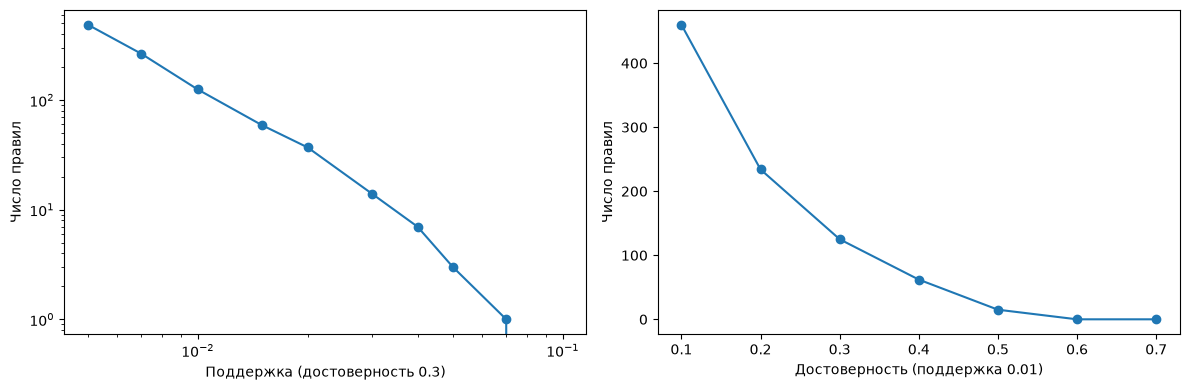

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(by_support['поддержка'], by_support['правил'], marker='o')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('Поддержка (достоверность 0.3)'); axes[0].set_ylabel('Число правил')
axes[1].plot(by_confidence['достоверность'], by_confidence['правил'], marker='o')
axes[1].set_xlabel('Достоверность (поддержка 0.01)'); axes[1].set_ylabel('Число правил')
plt.tight_layout()
plt.show()

Последовательно менял параметры FP-Growth. Сначала зафиксировал достоверность 0.3 и менял поддержку от 0.1 до 0.005, затем зафиксировал поддержку 0.01 и менял достоверность от 0.1 до 0.7.

Поддержка. При 0.1 правил нет (всего 8 частых наборов, только одиночные товары), при 0.07 одно правило, при 0.05 три, при 0.03 четырнадцать, при 0.01 их 125, а при 0.005 уже 487 на 1001 частом наборе. Число правил растёт быстрее, чем уменьшается порог. Средняя достоверность почти не меняется (0.37–0.43), а средний lift растёт с 1.43 при 0.05 до 2.17 при 0.005, максимальный lift с 1.57 до 4.72. При низкой поддержке правила опираются на небольшое число чеков, поэтому высокий lift нужно проверять на устойчивость.

Достоверность. При поддержке 0.01 число правил убывает с 460 при 0.1 до 15 при 0.5, а при 0.6 и выше правил нет: максимальная достоверность найденных правил ниже 0.6. Средняя достоверность оставшихся правил растёт с 0.24 до 0.54, средний lift растёт с 1.75 до 2.30.

Для этого датасета удобным компромиссом считаю поддержку 0.01–0.02 и достоверность 0.3–0.4: правил от нескольких десятков до сотни, их можно проанализировать вручную, а средний lift около 1.7–2.

## 7. Граф ассоциативных правил

C:\Users\Semen\AppData\Local\Temp\ipykernel_720\3465406996.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


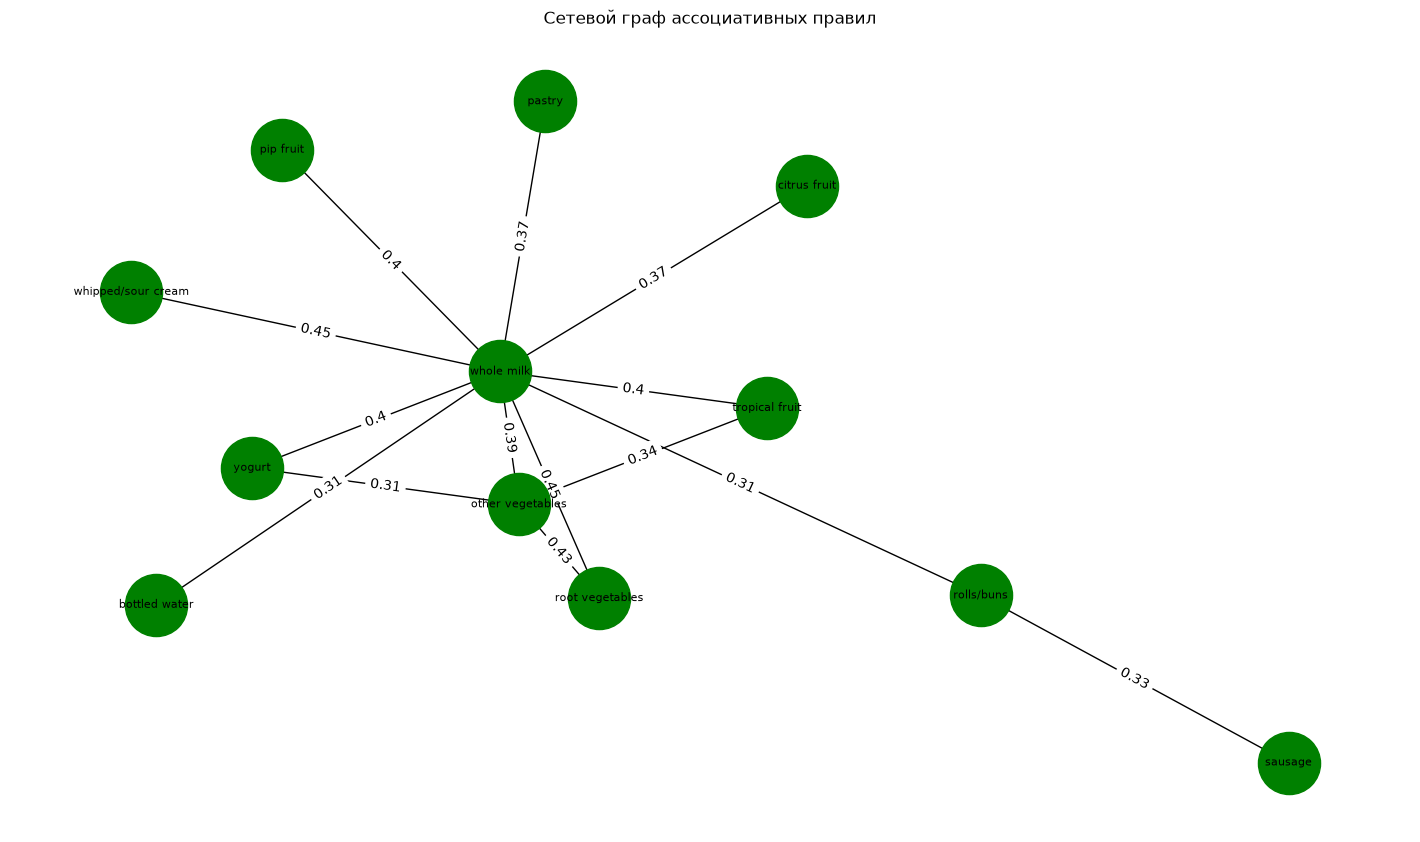

(12,
 14,
 14,
 whole milk          10
 other vegetables     4
 yogurt               2
 tropical fruit       2
 root vegetables      2
 dtype: int64)

In [18]:
G = nx.Graph()
for _, row in rules_fpg.iterrows():
    G.add_edge(', '.join(sorted(row['antecedents'])), ', '.join(sorted(row['consequents'])), weight=round(row['confidence'], 2))

plt.figure(figsize=(14, 8))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_size=2000, node_color='green', font_size=8)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'))
plt.title('Сетевой граф ассоциативных правил')
plt.tight_layout()
plt.show()

G.number_of_nodes(), G.number_of_edges(), len(rules_fpg), pd.Series(dict(G.degree())).sort_values(ascending=False).head(5)

Построил граф правил из п. 4: узлы — товары, рёбра — правила, подпись на ребре — достоверность. Округлил подписи до двух знаков и зафиксировал `seed` раскладки, чтобы граф не менялся между запусками. В графе 12 узлов и 14 рёбер, столько же, сколько правил.

Что можно извлечь из графа. Центральный узел `whole milk` соединён с десятью товарами, то есть он участвует в большинстве правил, но это отражает его популярность: во всех десяти правилах он стоит в следствии. Вторая группа — `other vegetables` (степень 4), он связан с `root vegetables`, `tropical fruit`, `yogurt` и `whole milk`, то есть свежие овощи и фрукты покупают вместе. Отдельная ветка — `rolls/buns` и `sausage`. Все 12 товаров образуют одну компоненту, и она держится на `whole milk`. По подписям на рёбрах видно силу связи по достоверности: от 0.31 (`bottled water`, `rolls/buns` с молоком) до 0.45 (`whipped/sour cream` и `root vegetables` с молоком).

Ограничения графа. Он неориентированный, поэтому не показывает направление правила, а если бы существовали правила A → B и B → A, они слились бы в одно ребро с последним записанным значением (в нашем случае таких пар нет). Кроме того, на нём нет lift и поддержки, а длина ребра зависит только от алгоритма раскладки и смысла не несёт.

## 8. Собственная визуализация правил и метрик

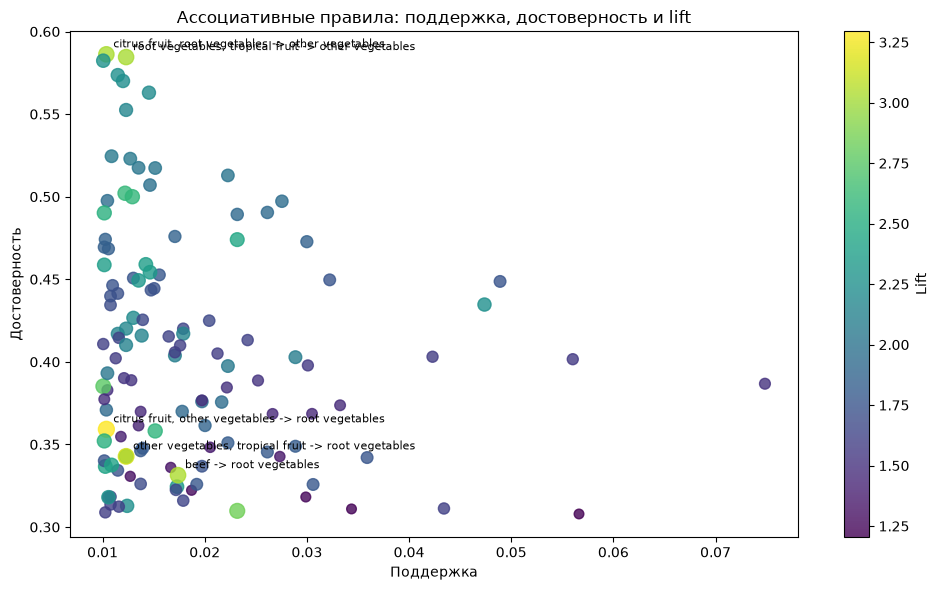

125

In [19]:
rules_wide = association_rules(fpgrowth(data, min_support=0.01, use_colnames=True), metric='confidence', min_threshold=0.3)

plt.figure(figsize=(10, 6))
sc = plt.scatter(rules_wide['support'], rules_wide['confidence'], c=rules_wide['lift'],
                 s=rules_wide['lift'] * 40, cmap='viridis', alpha=0.8)
plt.colorbar(sc, label='Lift')
for _, r in rules_wide.nlargest(5, 'lift').iterrows():
    plt.annotate(', '.join(sorted(r['antecedents'])) + ' -> ' + ', '.join(sorted(r['consequents'])),
                 (r['support'], r['confidence']), fontsize=8, xytext=(5, 5), textcoords='offset points')
plt.xlabel('Поддержка'); plt.ylabel('Достоверность')
plt.title('Ассоциативные правила: поддержка, достоверность и lift')
plt.tight_layout()
plt.show()

len(rules_wide)

Предложил два графика. Первый — диаграмма рассеяния всех правил, найденных при поддержке 0.01 и достоверности 0.3 (125 правил): по осям поддержка и достоверность, цвет и размер точки показывают lift, подписаны пять правил с наибольшим lift. В отличие от графика достоверности и графа, здесь на одном рисунке видны сразу три метрики.

Самые сильные правила расположены в области малой поддержки: `citrus fruit, other vegetables → root vegetables` (lift 3.30), `tropical fruit, other vegetables → root vegetables` (3.15), `beef → root vegetables` (3.04). Правила с наибольшей поддержкой (`yogurt`, `rolls/buns`, `other vegetables → whole milk`) имеют lift лишь 1.2–1.6. Из 125 правил 69 имеют по одному товару в посылке и 56 по два.

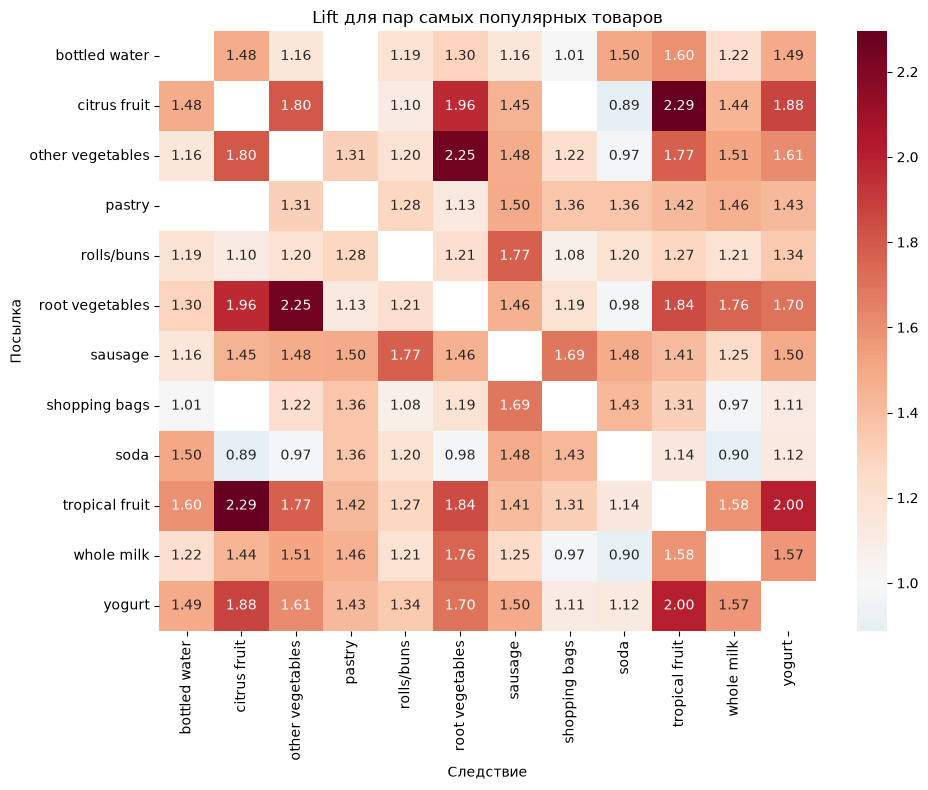

In [20]:
pairs = association_rules(fpgrowth(data, min_support=0.01, use_colnames=True), metric='lift', min_threshold=0)
pairs = pairs[(pairs['antecedents'].apply(len) == 1) & (pairs['consequents'].apply(len) == 1)]
pairs = pairs.assign(a=pairs['antecedents'].apply(lambda x: next(iter(x))), b=pairs['consequents'].apply(lambda x: next(iter(x))))
top12 = data.mean().nlargest(12).index
lift_matrix = pairs[pairs['a'].isin(top12) & pairs['b'].isin(top12)].pivot(index='a', columns='b', values='lift')

plt.figure(figsize=(10, 8))
sns.heatmap(lift_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=1)
plt.xlabel('Следствие'); plt.ylabel('Посылка')
plt.title('Lift для пар самых популярных товаров')
plt.tight_layout()
plt.show()

Второй график — тепловая карта lift для пар из 12 самых популярных товаров, посылка по строкам, следствие по столбцам. Пустые клетки означают, что поддержка пары ниже 0.01. Цветовая шкала центрирована на 1: красные клетки — товары покупают вместе чаще, чем при независимости, синие — реже.

Самые сильные пары: `citrus fruit` и `tropical fruit` (2.29), `other vegetables` и `root vegetables` (2.25), `tropical fruit` и `yogurt` (2.00). Единственные значения ниже 1 связаны с `soda`: с `citrus fruit` (0.89), `whole milk` (0.90), `other vegetables` (0.97) и `root vegetables` (0.98). Газировку покупают вместе с ними реже, чем можно было бы ожидать при независимости.

## Выводы

Исследовал методы поиска ассоциативных правил на датасете Groceries (9835 транзакций, 169 товаров, в среднем 4.4 товара в чеке).

С начальными параметрами (поддержка 0.03, достоверность 0.3) и Apriori, и FP-Growth нашли одни и те же 63 частых набора и 14 правил. Все правила имеют вид «один товар → один товар», lift у всех больше 1. Десять правил ведут к `whole milk`, и их достоверность во многом объясняется популярностью молока, поэтому оценивать правила только по достоверности нельзя, нужно смотреть на lift. Самое содержательное правило: `root vegetables → other vegetables` (lift 2.25).

Параметры сильно влияют на результат. Число правил падает при росте поддержки и достоверности: при достоверности 0.3 их 487 при поддержке 0.005 и ни одного при 0.1. При снижении поддержки растёт средний и максимальный lift, но правила опираются на малое число чеков. Минимальные пороги поддержки для наборов из 1, 2, 3 и 4 товаров: 0.2555, 0.0748, 0.0232 и 0.0078, поэтому правила с несколькими товарами в посылке требуют поддержки ниже 0.0232. Для этого датасета лучше всего подходят поддержка 0.01–0.02 и достоверность 0.3–0.4.

Граф показал центральную роль `whole milk` и группу овощей и фруктов вокруг `other vegetables`, но не отражает направление правил, lift и поддержку. Эти недостатки закрывают предложенные диаграмма рассеяния и тепловая карта lift.